# Install and Import Libraries

In [1]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import make_regression, make_classification
from tensorflow.keras.utils import to_categorical

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


##  Generate Synthetic Datasets & Train Quick Models

In [2]:
# 1. Regression Dataset (100 samples, 5 features)
X_reg, y_reg = make_regression(n_samples=100, n_features=5, noise=10.0, random_state=42)
# Simulate model predictions (actual values + small random error)
y_pred_reg = y_reg + np.random.normal(0, 5.0, size=y_reg.shape)

# 2. Binary Classification Dataset (100 samples, 2 classes: 0 or 1)
X_bin, y_bin = make_classification(
    n_samples=100, n_features=5, n_classes=2, random_state=42
)
# Simulate predicted probabilities between 0.01 and 0.99
y_pred_bin_prob = np.clip(
    np.abs(y_bin - np.random.uniform(0.05, 0.3, size=y_bin.shape)), 0.01, 0.99
)
# Simulate raw margin scores (-1 to +1) for Hinge loss
y_bin_hinge = np.where(y_bin == 0, -1.0, 1.0)
y_pred_hinge = y_bin_hinge * np.random.uniform(0.2, 1.5, size=y_bin.shape)

# 3. Multi-Class Classification Dataset (100 samples, 3 classes: 0, 1, 2)
X_cat, y_cat = make_classification(
    n_samples=100, n_features=5, n_classes=3, n_informative=3, random_state=42
)
# Convert labels to One-Hot Encoding (e.g., class 1 ->)
y_cat_onehot = to_categorical(y_cat, num_classes=3)
# Simulate softmax probability predictions across 3 classes
raw_scores = y_cat_onehot * 2.0 + np.random.uniform(0, 1.0, size=y_cat_onehot.shape)
y_pred_cat_prob = tf.nn.softmax(raw_scores).numpy()

print("All datasets and sample predictions generated successfully!")

All datasets and sample predictions generated successfully!


## Apply Regression Loss Functions One by One

In [3]:
# 1. Mean Squared Error (MSE)
mse_fn = tf.keras.losses.MeanSquaredError()
mse_value = mse_fn(y_reg, y_pred_reg).numpy()
print(f"1. Mean Squared Error (MSE): {mse_value:.4f}")

# 2. Mean Absolute Error (MAE)
mae_fn = tf.keras.losses.MeanAbsoluteError()
mae_value = mae_fn(y_reg, y_pred_reg).numpy()
print(f"2. Mean Absolute Error (MAE): {mae_value:.4f}")

# 3. Huber Loss (delta = 1.0)
huber_fn = tf.keras.losses.Huber(delta=1.0)
huber_value = huber_fn(y_reg, y_pred_reg).numpy()
print(f"3. Huber Loss:                {huber_value:.4f}")

1. Mean Squared Error (MSE): 26.7972
2. Mean Absolute Error (MAE): 4.2795
3. Huber Loss:                3.8039


## Apply Classification Loss Functions One by One

In [4]:
# 4. Binary Cross-Entropy (Log Loss)
bce_fn = tf.keras.losses.BinaryCrossentropy()
bce_value = bce_fn(y_bin, y_pred_bin_prob).numpy()
print(f"4. Binary Cross-Entropy:      {bce_value:.4f}")

# 5. Categorical Cross-Entropy (Multi-class)
cce_fn = tf.keras.losses.CategoricalCrossentropy()
cce_value = cce_fn(y_cat_onehot, y_pred_cat_prob).numpy()
print(f"5. Categorical Cross-Entropy: {cce_value:.4f}")

# 6. Hinge Loss (SVM-style margin loss, expects -1 and 1)
hinge_fn = tf.keras.losses.Hinge()
hinge_value = hinge_fn(y_bin_hinge, y_pred_hinge).numpy()
print(f"6. Hinge Loss:                {hinge_value:.4f}")

4. Binary Cross-Entropy:      0.1989
5. Categorical Cross-Entropy: 0.2586
6. Hinge Loss:                0.2496


## Import Visualization Libraries


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme for all plots
sns.set_theme(style="whitegrid")

## Plot the Synthetic Datasets (Regression & Classification)

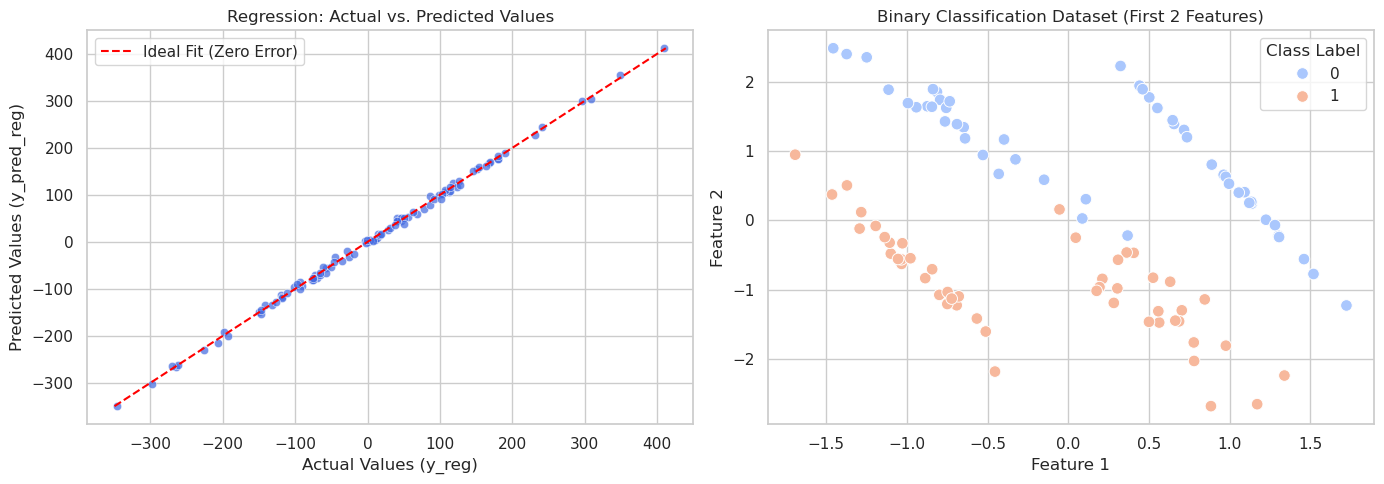

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Regression Dataset (Actual vs. Predicted Values)
sns.scatterplot(x=y_reg, y=y_pred_reg, ax=axes[0], color="royalblue", alpha=0.7)
# Plot ideal diagonal line (where y_pred == y_true)
min_val, max_val = min(y_reg.min(), y_pred_reg.min()), max(
    y_reg.max(), y_pred_reg.max()
)
axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Ideal Fit (Zero Error)",
)
axes[0].set_title("Regression: Actual vs. Predicted Values")
axes[0].set_xlabel("Actual Values (y_reg)")
axes[0].set_ylabel("Predicted Values (y_pred_reg)")
axes[0].legend()

# Plot 2: Binary Classification Dataset (Feature 1 vs. Feature 2)
sns.scatterplot(
    x=X_bin[:, 0], y=X_bin[:, 1], hue=y_bin, palette="coolwarm", ax=axes[1], s=70
)
axes[1].set_title("Binary Classification Dataset (First 2 Features)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend(title="Class Label")

plt.tight_layout()
plt.show()

## Compare Loss Function Curves Visually


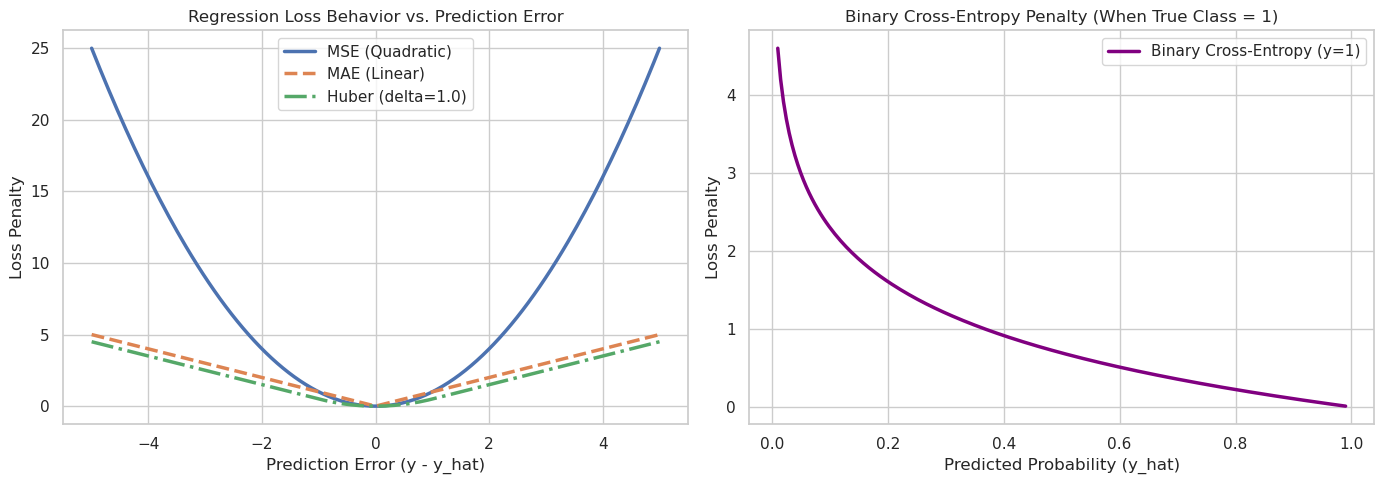

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Panel 1: Regression Loss Curves (Error from -5 to +5) ---
errors = np.linspace(-5, 5, 200)
y_true_zero = np.zeros_like(errors)

# Calculate point-by-point losses
mse_curve = errors**2
mae_curve = np.abs(errors)
huber_curve = np.where(
    np.abs(errors) <= 1.0, 0.5 * errors**2, 1.0 * (np.abs(errors) - 0.5)
)

axes[0].plot(errors, mse_curve, label="MSE (Quadratic)", linewidth=2.5)
axes[0].plot(errors, mae_curve, label="MAE (Linear)", linewidth=2.5, linestyle="--")
axes[0].plot(
    errors, huber_curve, label="Huber (delta=1.0)", linewidth=2.5, linestyle="-."
)
axes[0].set_title("Regression Loss Behavior vs. Prediction Error")
axes[0].set_xlabel("Prediction Error (y - y_hat)")
axes[0].set_ylabel("Loss Penalty")
axes[0].legend()

# --- Panel 2: Classification Loss Curves (True Class = 1) ---
probs = np.linspace(0.01, 0.99, 200)
margins = np.linspace(-2, 2, 200)

# BCE when true label is 1: -log(p)
bce_curve = -np.log(probs)
# Hinge loss when true label is +1: max(0, 1 - margin)
hinge_curve = np.maximum(0, 1 - margins)

axes[1].plot(
    probs, bce_curve, label="Binary Cross-Entropy (y=1)", color="purple", linewidth=2.5
)
axes[1].set_title("Binary Cross-Entropy Penalty (When True Class = 1)")
axes[1].set_xlabel("Predicted Probability (y_hat)")
axes[1].set_ylabel("Loss Penalty")
axes[1].legend()

plt.tight_layout()
plt.show()

## Bar Chart of Calculated Loss Values

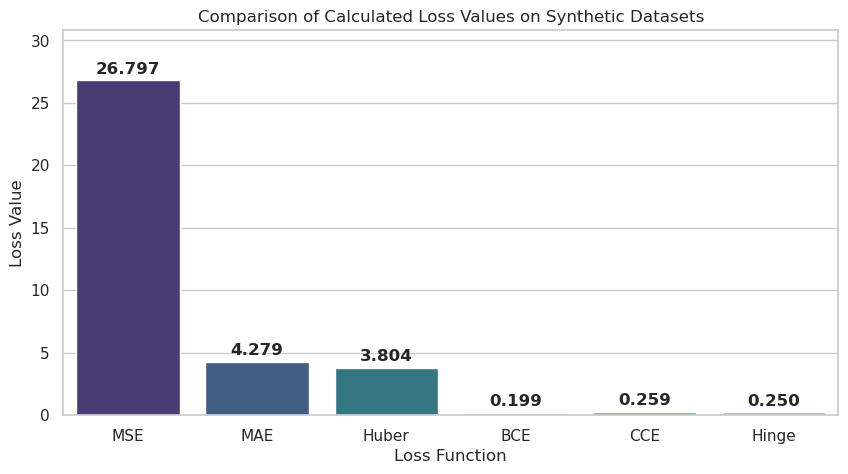

In [8]:
loss_names = ["MSE", "MAE", "Huber", "BCE", "CCE", "Hinge"]
loss_values = [mse_value, mae_value, huber_value, bce_value, cce_value, hinge_value]

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=loss_names, y=loss_values, palette="viridis", hue=loss_names, legend=False
)

# Add exact value labels on top of each bar
for i, v in enumerate(loss_values):
    ax.text(
        i, v + (max(loss_values) * 0.02), f"{v:.3f}", ha="center", fontweight="bold"
    )

plt.title("Comparison of Calculated Loss Values on Synthetic Datasets")
plt.ylabel("Loss Value")
plt.xlabel("Loss Function")
plt.ylim(0, max(loss_values) * 1.15)
plt.show()

## Train a Keras Model & Plot Epoch-by-Epoch Training Loss

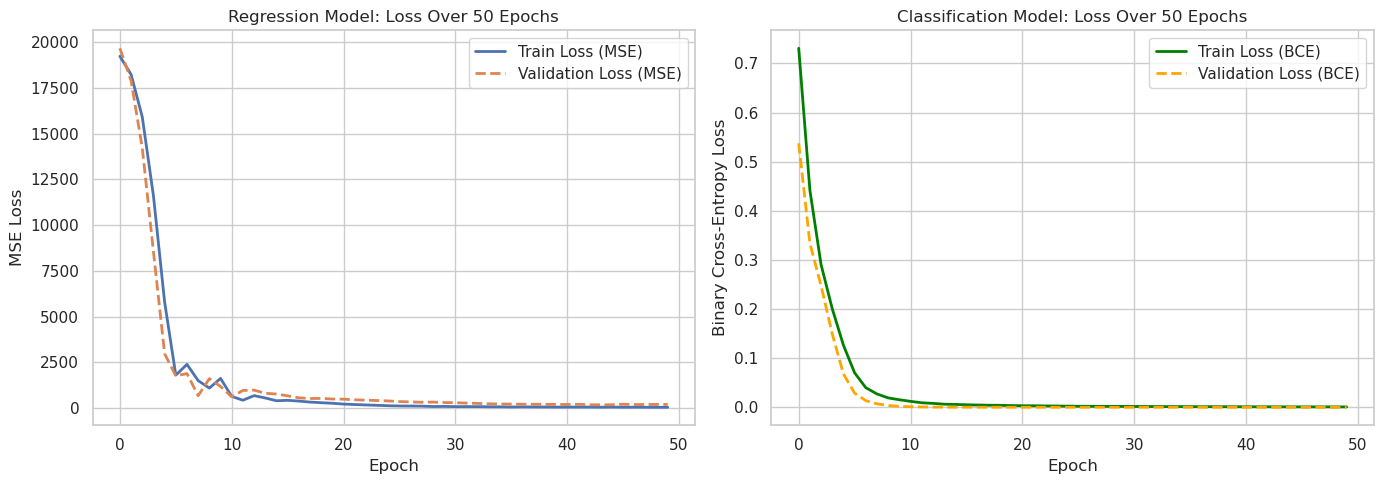

In [9]:
from sklearn.model_selection import train_test_split

# 1. Split datasets into Train (80%) and Validation (20%)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
Xb_train, Xb_val, yb_train, yb_val = train_test_split(
    X_bin, y_bin, test_size=0.2, random_state=42
)

# 2. Build & Train Regression Model (Using MSE Loss)
reg_model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(5,)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ]
)
reg_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.05), loss="mse")
reg_history = reg_model.fit(
    Xr_train, yr_train, validation_data=(Xr_val, yr_val), epochs=50, verbose=0
)

# 3. Build & Train Binary Classification Model (Using Binary Cross-Entropy)
bin_model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(5,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ]
)
bin_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.02), loss="binary_crossentropy"
)
bin_history = bin_model.fit(
    Xb_train, yb_train, validation_data=(Xb_val, yb_val), epochs=50, verbose=0
)

# 4. Plot Training vs. Validation Loss Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Regression Loss Curve
axes[0].plot(reg_history.history["loss"], label="Train Loss (MSE)", linewidth=2)
axes[0].plot(
    reg_history.history["val_loss"],
    label="Validation Loss (MSE)",
    linestyle="--",
    linewidth=2,
)
axes[0].set_title("Regression Model: Loss Over 50 Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].legend()

# Classification Loss Curve
axes[1].plot(
    bin_history.history["loss"], label="Train Loss (BCE)", linewidth=2, color="green"
)
axes[1].plot(
    bin_history.history["val_loss"],
    label="Validation Loss (BCE)",
    linestyle="--",
    linewidth=2,
    color="orange",
)
axes[1].set_title("Classification Model: Loss Over 50 Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

##  Plot Confusion Matrix Heatmap

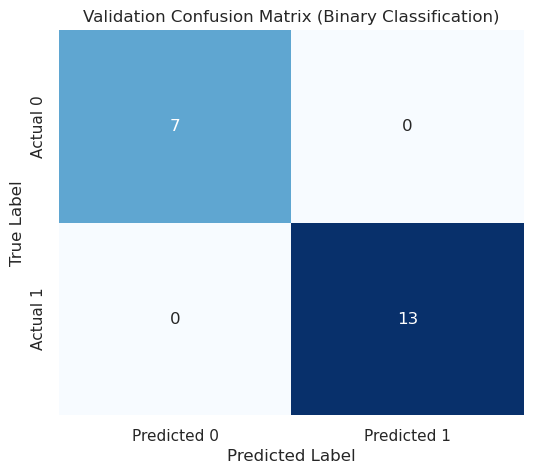

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         7
           1       1.00      1.00      1.00        13

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [10]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict probabilities and convert to binary class labels (0 or 1)
y_val_probs = bin_model.predict(Xb_val, verbose=0)
y_val_preds = (y_val_probs > 0.5).astype(int).flatten()

# Generate Confusion Matrix
cm = confusion_matrix(yb_val, y_val_preds)

# Plot Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"],
)
plt.title("Validation Confusion Matrix (Binary Classification)")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

# Print detailed precision, recall, and F1-score
print(classification_report(yb_val, y_val_preds))